# QuickQuake catalog visualization: Pavlof 2021 example

Run `QQ_driver.py` in this folder first: it downloads 16 hours of data (2021-07-29 08:00 to 2021-07-30 00:00 UTC) and writes the results in `data/` next to this notebook.

Figures to look at the results of a QuickQuake run. All the logic lives in `qq_helpers.py`;
this notebook only sets paths, loads the results, calls plotting functions and (optionally)
saves the figures in `DATA_ROOT/images/visualization/`. Edit the **Settings** cell, then run all
cells. The analysis figures (magnitude of completeness, FI, comparison with reference catalogs,
DBSCAN clusters) are in `catalog_analysis.ipynb`.

**Kernel:** the QuickQuake conda environment (the one `install.sh` creates). In VS Code select it as the kernel; in a terminal run `conda activate <environment>` and then `jupyter lab`.

| Section | Figures |
|---|---|
| 2 | Event counts, 2-D map, stations, zoomed map, timeline with spans, cross section |
| 3 | 3-D views (time colours, monthly, interactive) |
| 4 | Waveforms: move-outs and spectrograms |
| 5 | Location changes GaMMA -> HypoInverse -> HypoDD |

In [2]:
from pathlib import Path
import sys
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio

# This notebook lives in <QuickQuake>/examples/pavlof_2021/; qq_helpers.py is in <QuickQuake>/quickquake/
HELPERS_DIR = (Path.cwd() / "../../quickquake").resolve()
if str(HELPERS_DIR) not in sys.path:
    sys.path.insert(0, str(HELPERS_DIR))

import qq_helpers as h
importlib.reload(h)
print("helpers:", h.__file__)

pio.renderers.default = "plotly_mimetype+notebook_connected"   # interactive figures in VS Code and Jupyter

helpers: /home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py


## 0. Settings
Everything you normally edit is in this cell.

In [3]:
# ---------------- results of a QuickQuake run ----------------
# Relative paths are relative to this notebook's folder (examples/pavlof_2021/).
DATA_ROOT = Path("data").resolve()                           # written by QQ_driver.py in this folder
NAMEBASE = "GAMMA"                                           # same as location_namebase in QQ_driver.py
REGION = {"name": "Pavlof", "lat": 55.4133, "lon": -161.8903}   # volcano / region centre (degrees)
RADIUS_KM = None              # keep only events within this distance (km) of the centre; None = keep all
START = "2021-07-29T08:00:00Z"     # same window as START / END in QQ_driver.py
END   = "2021-07-30T00:00:00Z"

# ---------------- what to draw ----------------
SAVE_FIGURES = True           # save into DATA_ROOT/images/visualization/
DEPTH_MAX_KM = 40.0           # deepest event shown in depth-coloured / 3-D figures (km)
N_WAVEFORM_EVENTS = 3         # events drawn in the move-out and spectrogram sections
SPANS = []                    # (start, end, label) periods, e.g. ("2021-08-05", "2021-08-06", "Ash emissions")
PROFILE = None                # cross section: dict(start_lon, start_lat, end_lon, end_lat, label_start, label_end, swath_km)

# ---------------- paths inside DATA_ROOT (standard QuickQuake layout) ----------------
MERGED = DATA_ROOT / "merged"
CATALOG_CSV   = MERGED / f"output/{NAMEBASE}_hypodd_catalog_qcfiltered.csv"   # final QuickQuake catalog
HYPODD_CSV    = MERGED / f"output/{NAMEBASE}_hypodd_catalog.csv"
HYPOINV_CSV   = MERGED / f"output/{NAMEBASE}_hypoinv_good.csv"
GAMMA_CSV     = MERGED / f"input/{NAMEBASE}_catalog_cleaned.csv"
PICKS_CSV     = MERGED / f"input/{NAMEBASE}_picks_cleaned.csv"
STATIONS_JSON = MERGED / f"input/{NAMEBASE}_station_list.json"
WAVEFORM_INDEX = DATA_ROOT / "waveform_index.pkl"


IMAGE_DIR = h.ensure_dir(DATA_ROOT / "images" / "visualization")


def save(fig, name, **kwargs):
    """Save a figure into IMAGE_DIR when SAVE_FIGURES is True."""
    if SAVE_FIGURES and fig is not None:
        out = IMAGE_DIR / name
        if hasattr(fig, "write_html"):
            fig.write_html(out, include_plotlyjs="cdn")
        else:
            fig.savefig(out, bbox_inches="tight", **kwargs)
        print("saved:", out)

## 1. Load the catalog and the stations

In [4]:
catc = h.CatalogCols(time="time", lat="latitude", lon="longitude", depth_km="depth_km", mag="magnitude")
stc = h.StationCols(station_id="station", lat="latitude", lon="longitude", elev_km="elev_km")

df_catalog = h.load_catalog_csv(CATALOG_CSV, catc=catc)
df_stations = h.load_stations_json(STATIONS_JSON)
print(f"catalog: {len(df_catalog)} events | stations: {len(df_stations)}")

if RADIUS_KM is not None:
    df_catalog = h.filter_catalog_by_radius(df_catalog, center_lat=REGION["lat"], center_lon=REGION["lon"],
                                            radius_km=RADIUS_KM, lat_col=catc.lat, lon_col=catc.lon)
    print(f"within {RADIUS_KM:g} km of {REGION['name']}: {len(df_catalog)} events "
          f"(farthest {df_catalog['r_km'].max():.2f} km)")

print("time range:", df_catalog[catc.time].min(), "->", df_catalog[catc.time].max())

catalog: 38 events | stations: 11
time range: 2021-07-29 08:09:35.700000+00:00 -> 2021-07-29 23:38:45.540000+00:00


## 2. Catalog maps and timelines

saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/event_count_daily.svg


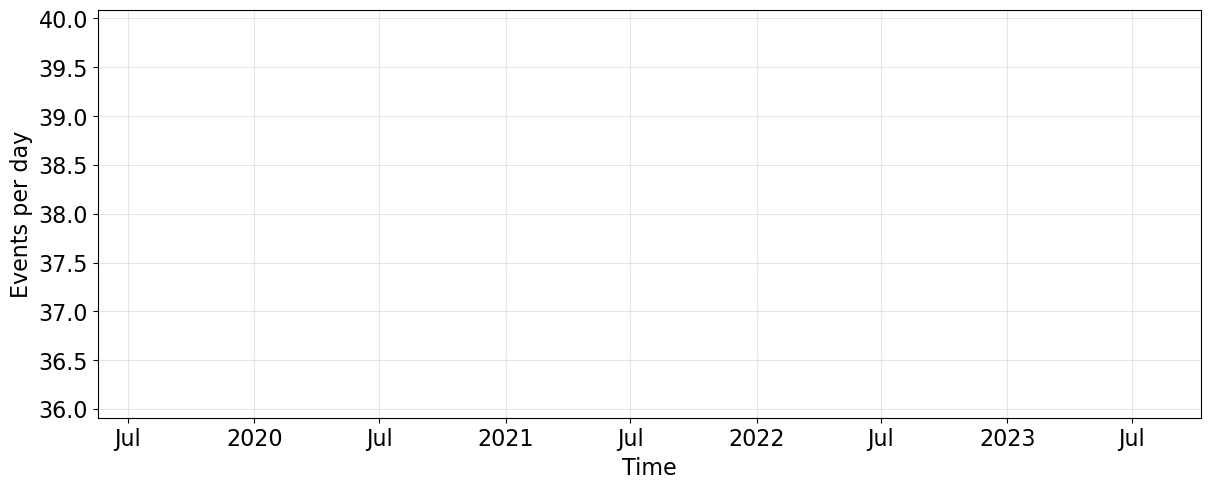

In [5]:
fig, ax, counts = h.plot_event_count_time(catalog=df_catalog, time_col=catc.time, start=START, end=END,
                                          freq="D", figsize=(12, 5))
save(fig, "event_count_daily.svg")
plt.show()

Pavlof seismicity map from 2021-07-29 to 2021-07-30 (Size = Magnitude | Color = Depth)
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/mapview_seismicity.svg


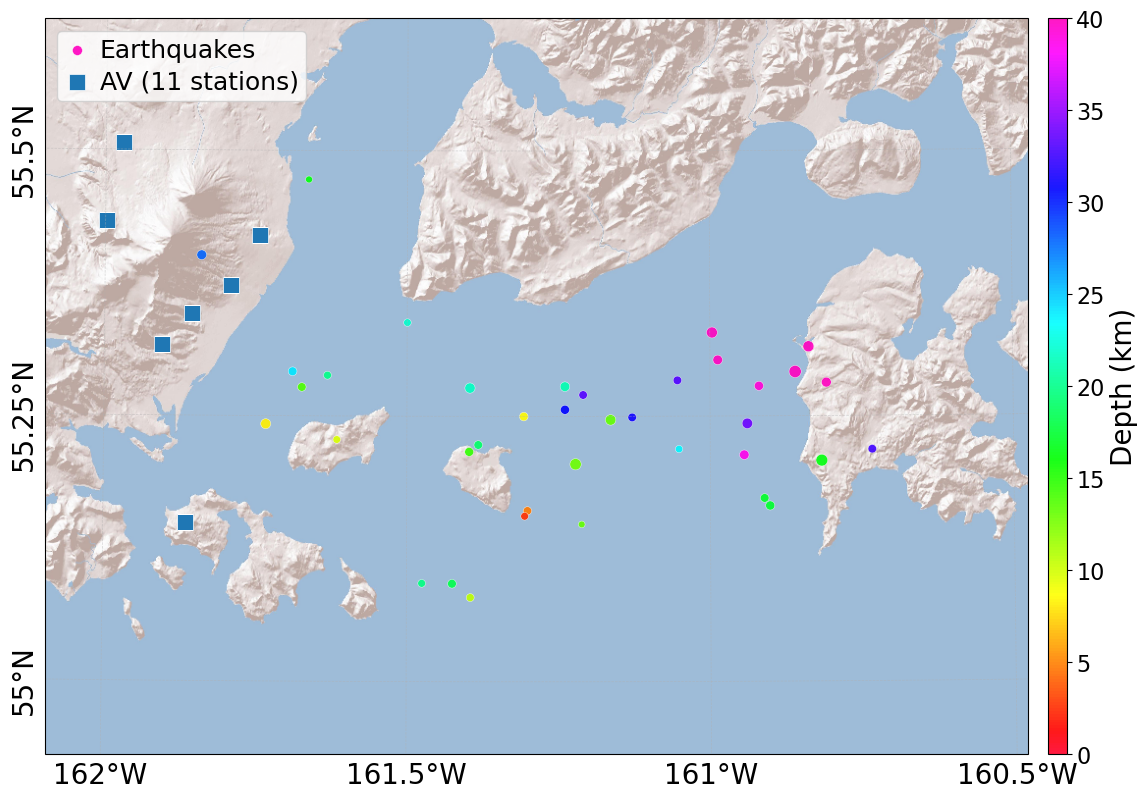

In [6]:
fig, ax = h.plot_mapview_seismicity(catalog=df_catalog, stations=df_stations, start=START, end=END,
                                    depth_vmin=0.0, depth_vmax=DEPTH_MAX_KM, region_name=REGION["name"],
                                    relief_zoom=12, figsize=(15, 8), savefig=False)
save(fig, "mapview_seismicity.svg")
plt.show()

Basemap from 2021-07-29 to 2021-07-30 without seismicity
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/mapview_stations_only.svg


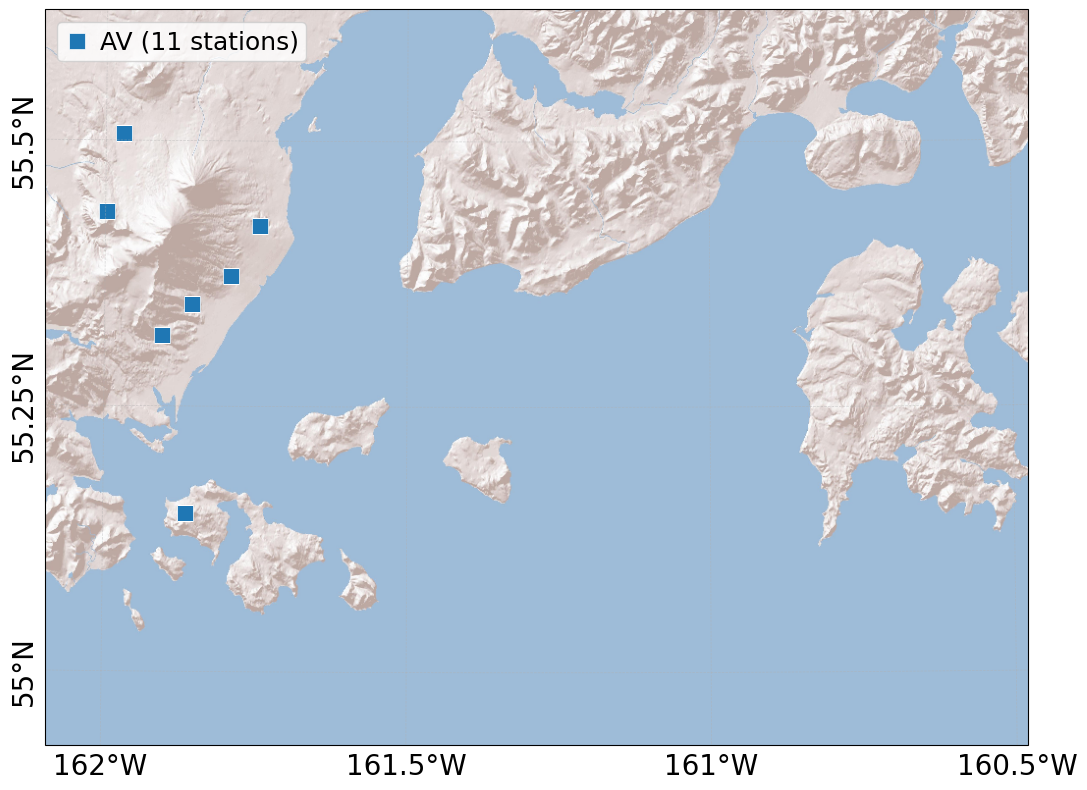

In [7]:
fig, ax = h.plot_mapview_basemap_stations(catalog=df_catalog, stations=df_stations, start=START, end=END,
                                          relief_zoom=12, figsize=(15, 8), savefig=False)
save(fig, "mapview_stations_only.svg")
plt.show()

Seismicity map from 2021-07-29 to 2021-07-30 (Size = Magnitude | Color = Depth)
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/mapview_zoom.svg


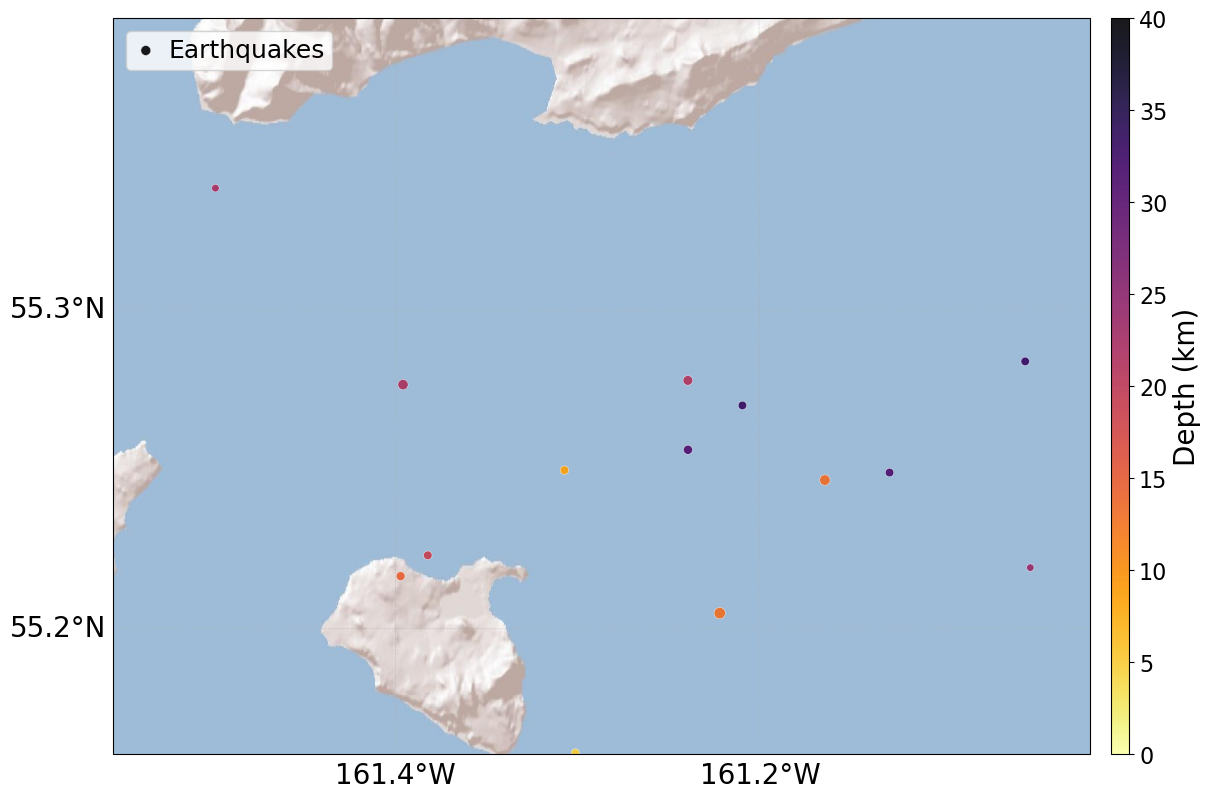

{'bounds': (-161.55463333333333, -161.01883666666666, 55.160373, 55.391482), 'center': (-161.286735, 55.2759275), 'n_events': 38, 'depth_filter_min': None, 'depth_filter_max': None}


In [8]:
fig, ax, meta = h.plot_mapview_seismicity_zoom(catalog=df_catalog, start=START, end=END,
                                               depth_vmin=0.0, depth_vmax=DEPTH_MAX_KM, cmap_name="inferno_r",
                                               relief_zoom=12, step_lon=0.2, step_lat=0.1, figsize=(15, 8),
                                               zoom_factor=3, show=False)
save(fig, "mapview_zoom.svg")
plt.show()
print(meta)

saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/timeline_histogram.svg


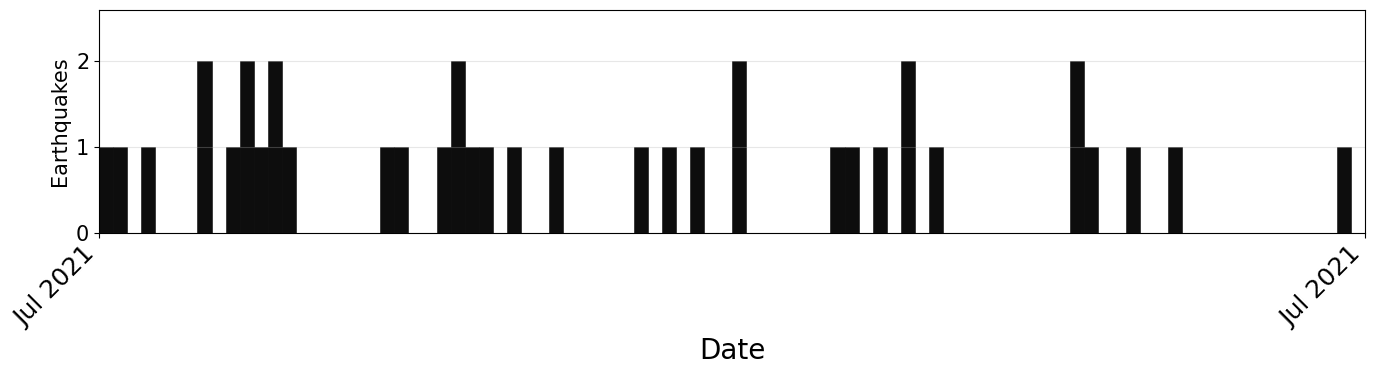

In [9]:
fig, ax, meta = h.plot_timeline_histogram(catalog=df_catalog, start=START, end=END, spans=SPANS,
                                          time_col=catc.time, fi_col="FI", n_bins=90, figsize=(14, 4),
                                          show_legend=bool(SPANS), savefig=False)
save(fig, "timeline_histogram.svg")
plt.show()

In [10]:
if PROFILE is None:
    print("cross section skipped: set PROFILE in the Settings cell")
else:
    fig, ax = h.plot_mapview_seismicity(catalog=df_catalog, stations=df_stations, start=START, end=END,
                                        depth_vmin=0.0, depth_vmax=DEPTH_MAX_KM, region_name=REGION["name"],
                                        relief_zoom=12, figsize=(15, 8), savefig=False)
    h.add_profile_line(ax=ax, start_lon=PROFILE["start_lon"], start_lat=PROFILE["start_lat"],
                       end_lon=PROFILE["end_lon"], end_lat=PROFILE["end_lat"],
                       start_label=PROFILE["label_start"], end_label=PROFILE["label_end"],
                       line_color="red", line_width=3.0, marker_size=80, fontsize=16)
    save(fig, "mapview_seismicity_with_crosssection.svg")
    plt.show()

    fig, ax, meta = h.plot_cross_section_seismicity(
        catalog=df_catalog, start=START, end=END, catc=catc,
        start_lon=PROFILE["start_lon"], start_lat=PROFILE["start_lat"],
        end_lon=PROFILE["end_lon"], end_lat=PROFILE["end_lat"], swath_km=PROFILE["swath_km"],
        depth_vmin=0.0, depth_vmax=DEPTH_MAX_KM, depth_max_plot=DEPTH_MAX_KM, cmap_name="inferno_r",
        x_label_start=PROFILE["label_start"], x_label_end=PROFILE["label_end"], figsize=(12, 6))
    save(fig, "cross_section.svg")
    plt.show()
    print(meta)

cross section skipped: set PROFILE in the Settings cell


## 3. 3-D views

Number of events after filters (time, depth<=40.0 km): 33


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:2177: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  df["_t_num"] = mdates.date2num(df["_t"].dt.to_pydatetime())


saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/mapview3d_timecolor.svg


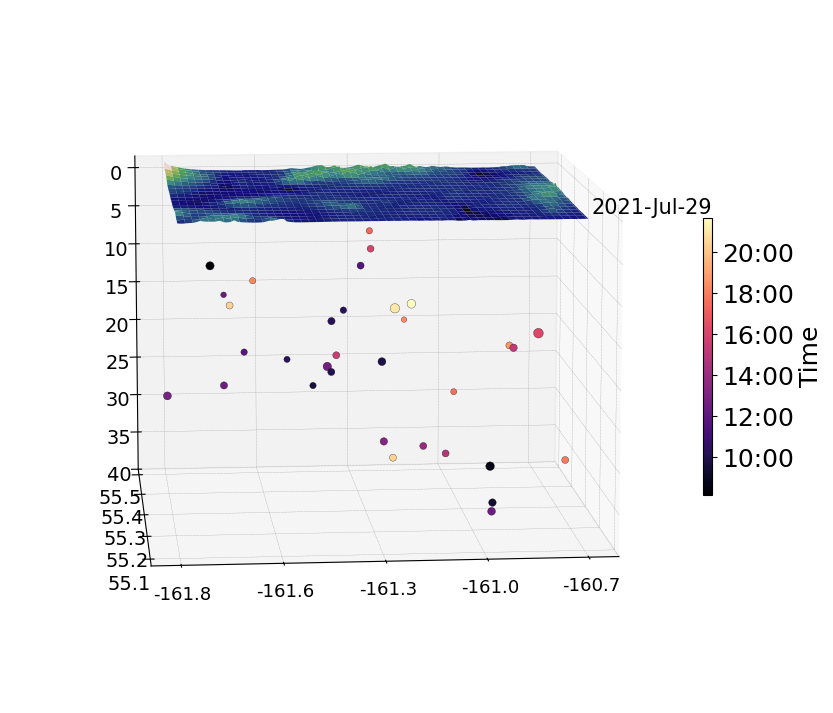

In [11]:
fig, ax, meta = h.plot_mapview3d_timecolor(catalog=df_catalog, start=START, end=END, depth_max=DEPTH_MAX_KM,
                                           dem_res="15s", exagg=1.0, view_elev=10.0, view_azim=265.0,
                                           figsize=(12, 9), savefig=False, catc=catc)
save(fig, "mapview3d_timecolor.svg")
plt.show()

Number of events after filters (time, depth<=40.0 km): 33
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/mapview3d_months.svg


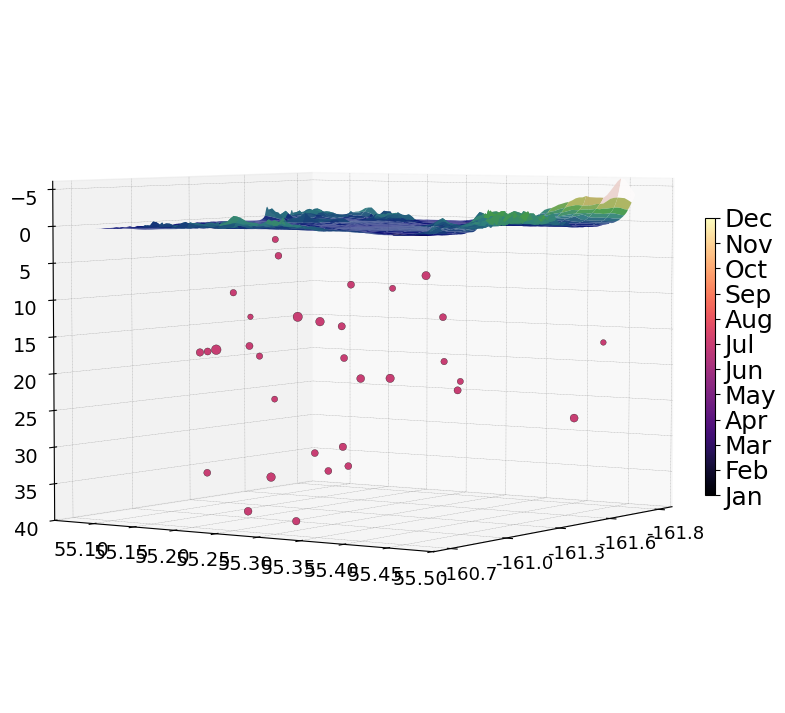

events plotted: 33


In [12]:
fig, ax, meta = h.plot_mapview3d_months(catalog=df_catalog, start=START, end=END, depth_max=DEPTH_MAX_KM,
                                        exagg=4, view_elev=4, view_azim=34, dem_res="15s", savefig=False)
save(fig, "mapview3d_months.svg")
plt.show()
print("events plotted:", meta["n_events"])

In [13]:
fig = h.plot_catalog_3d_topo_seismicity(catalog=df_catalog, catc=catc, mode="time", dem_res="15s",
                                        region_name=REGION["name"], show=False)
save(fig, "catalog_3d_interactive.html")
fig.show()

saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/catalog_3d_interactive.html


## 4. Waveforms: move-outs and spectrograms
Needs the waveform chunks of the run (`DATA_ROOT/<chunk>/waveforms/*.mseed`) and the cleaned picks.

In [14]:
has_waveforms = PICKS_CSV.exists() and (WAVEFORM_INDEX.exists() or any(DATA_ROOT.glob("*/waveforms/*.mseed")))
if not has_waveforms:
    print("waveform sections skipped: no picks file or no waveforms under DATA_ROOT")
else:
    wf_catalog, wf_picks, wf_stations = h.load_inputs(CATALOG_CSV, PICKS_CSV, STATIONS_JSON)
    if WAVEFORM_INDEX.exists():
        wf_index = h.WaveformIndex.load(WAVEFORM_INDEX)
    else:
        wf_index = h.WaveformIndex.build([DATA_ROOT], glob_pattern="**/waveforms/*.mseed")
        wf_index.save(WAVEFORM_INDEX)
    stream_cache = h.StreamCache()
    print("indexed mseed files:", len(wf_index.df))

indexed mseed files: 2


saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/moveout_event_0.svg


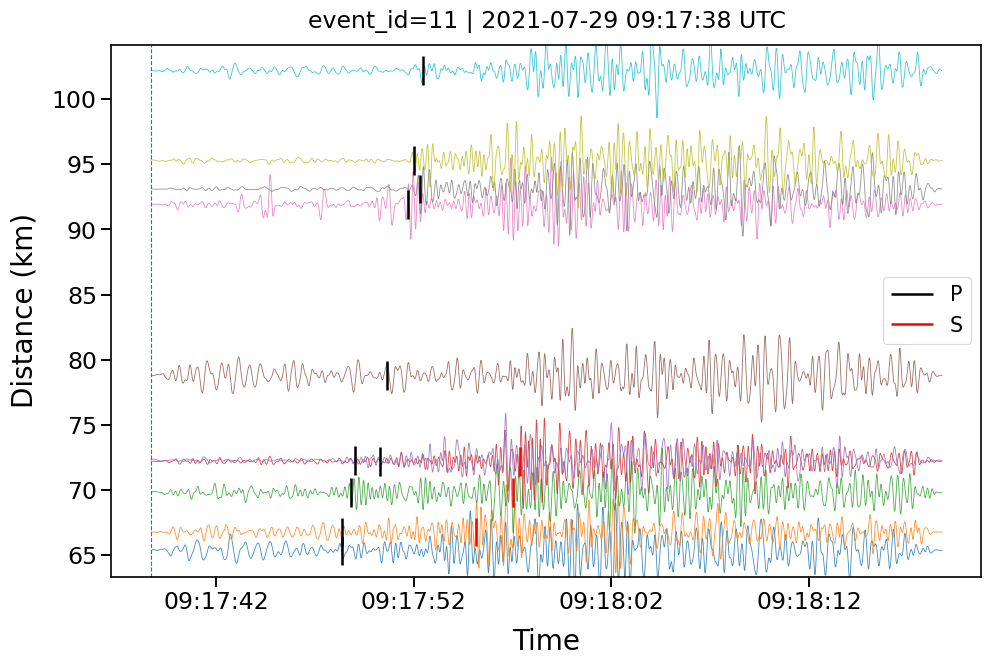

0 stations used: 10
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/moveout_event_1.svg


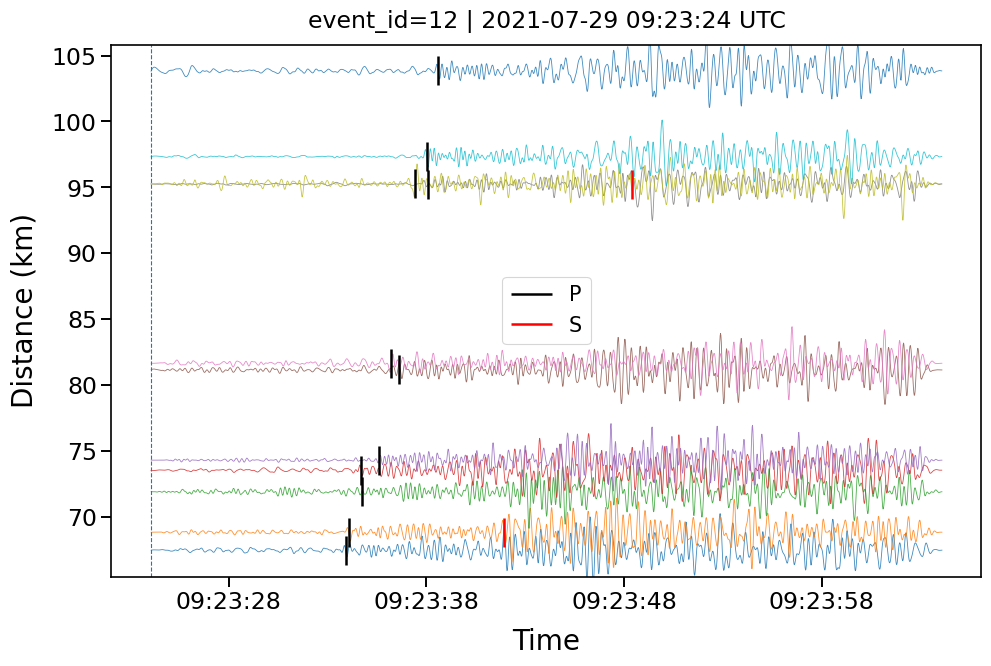

1 stations used: 11
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/moveout_event_2.svg


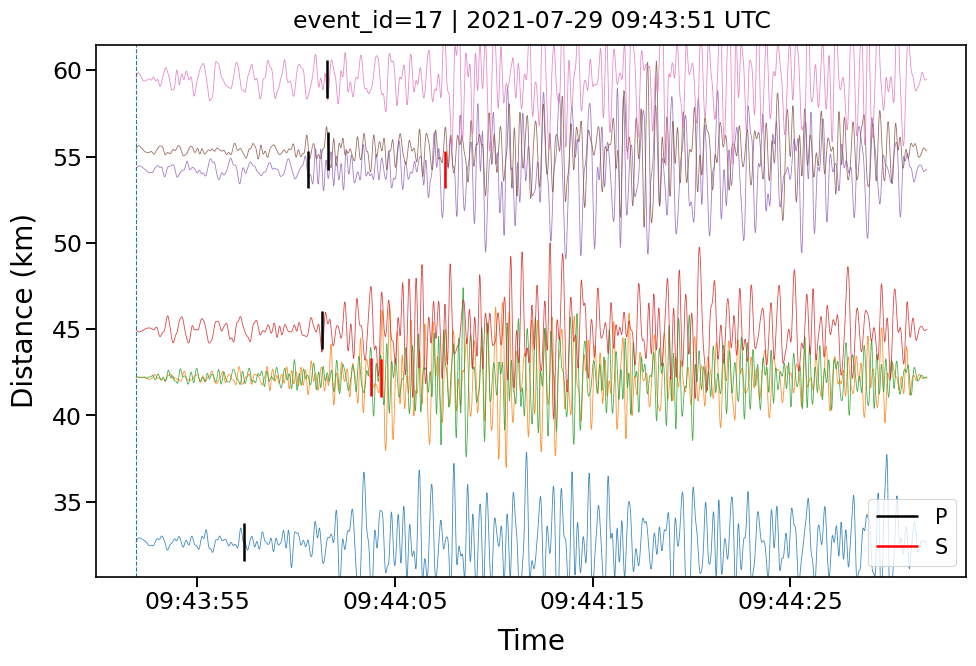

2 stations used: 7


In [15]:
if has_waveforms:
    for row_idx, row_event in wf_catalog.iloc[:N_WAVEFORM_EVENTS].iterrows():
        fig, ax, meta = h.plot_event_moveout_pretty(
            row_event=row_event, picks=wf_picks, stations=wf_stations, cache=stream_cache, wf_index=wf_index,
            pre_s=0, post_s=40, freqmin=1.0, freqmax=5.0, figsize=(10, 7))
        save(fig, f"moveout_event_{row_idx}.svg")
        plt.show()
        print(row_idx, "stations used:", len(meta["stations_used"]))

/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:8159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/spectrograms_event_0.png


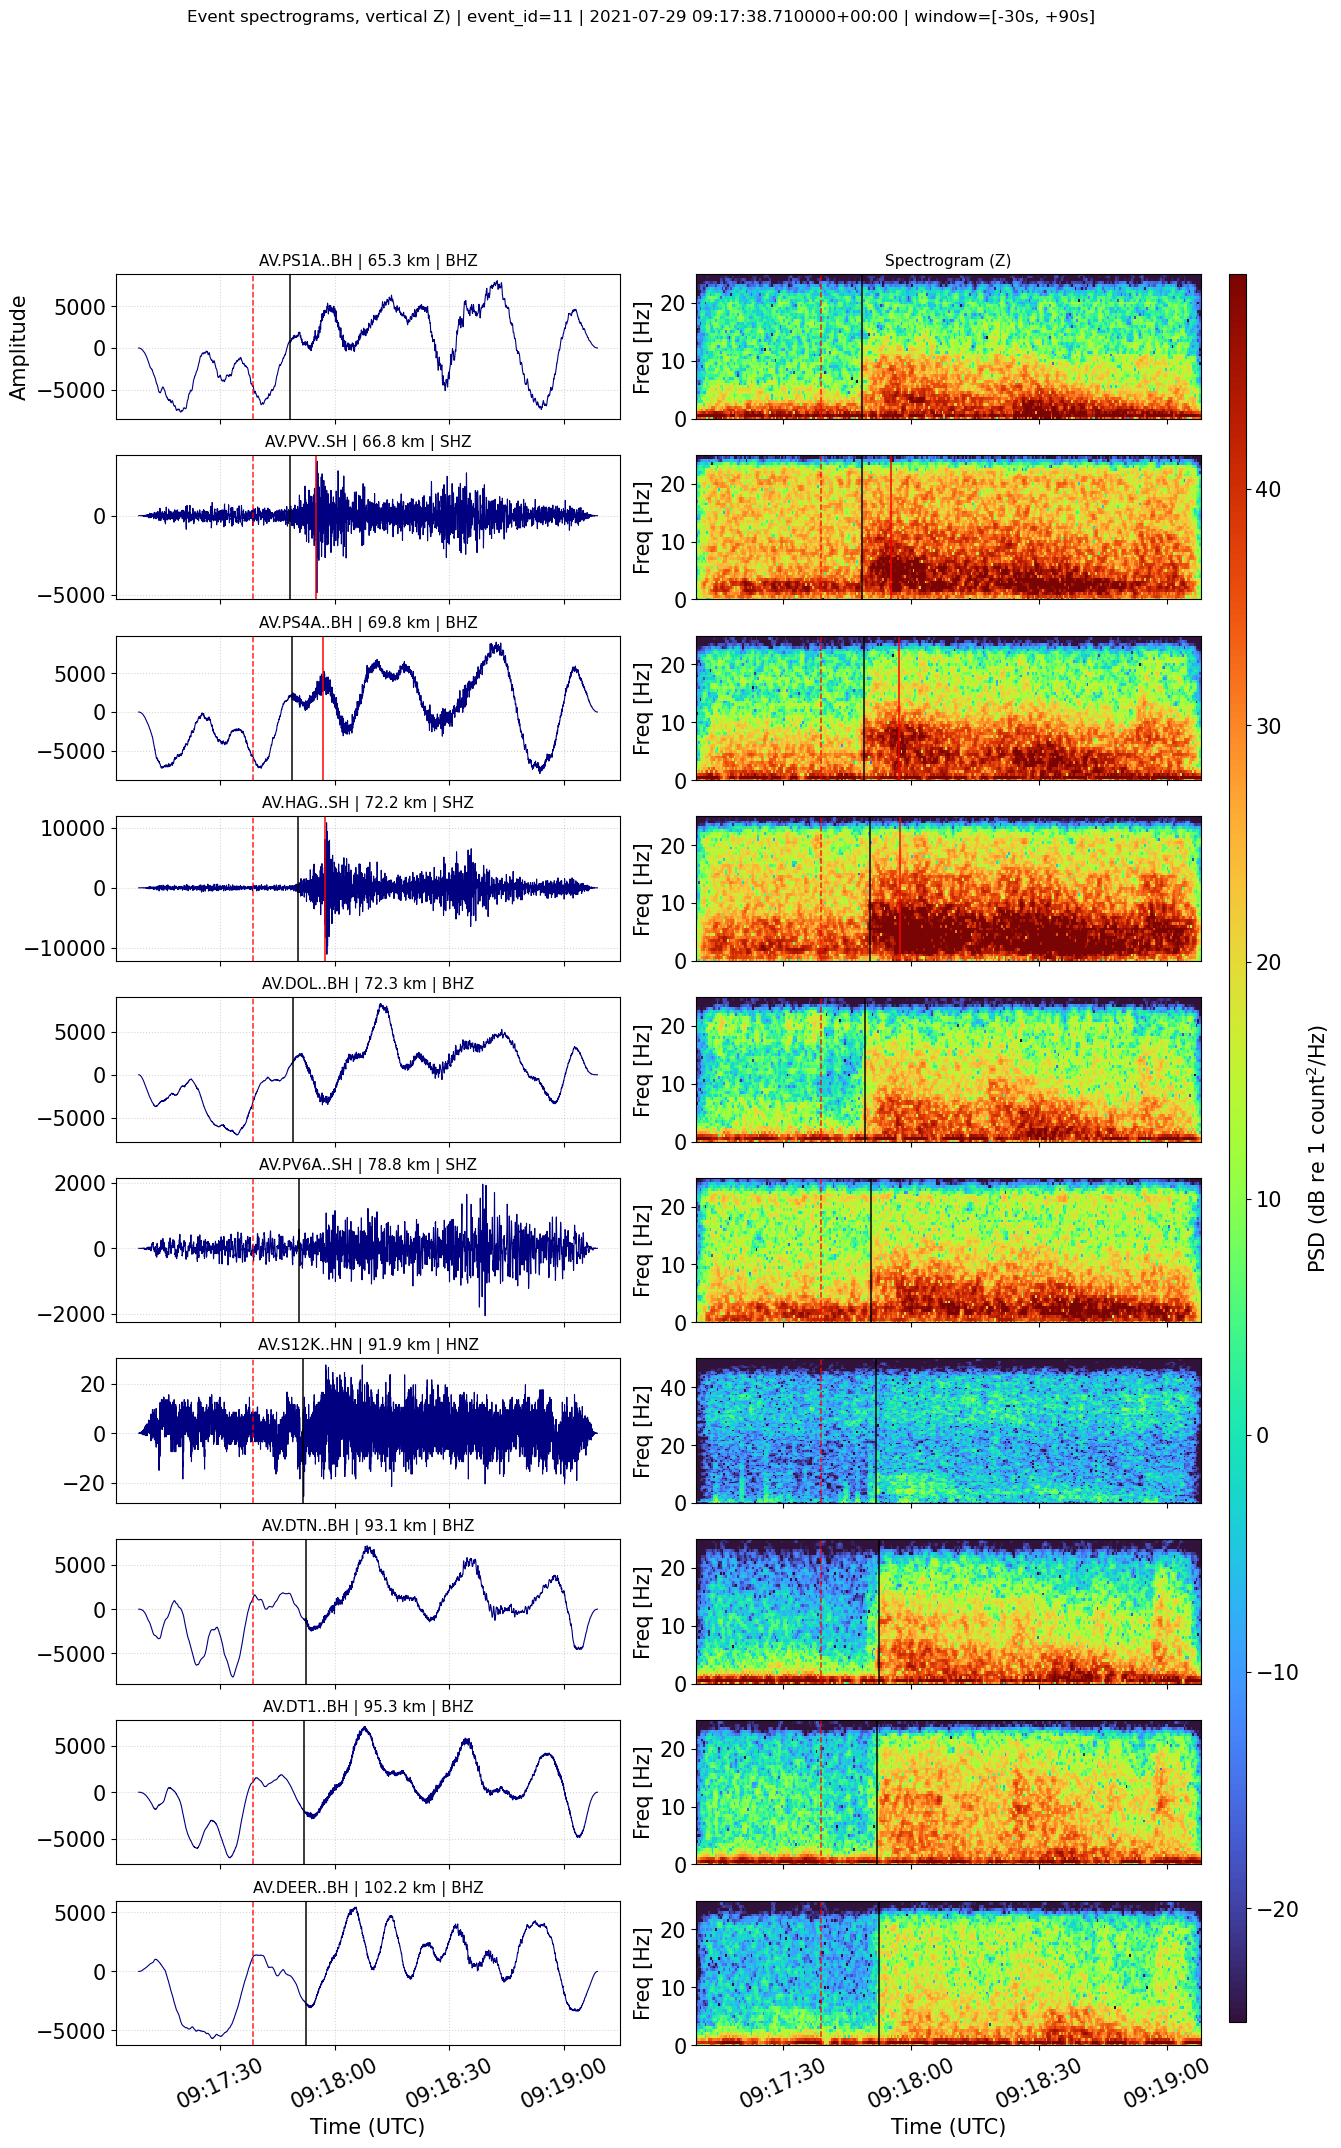

/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:8159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/spectrograms_event_1.png


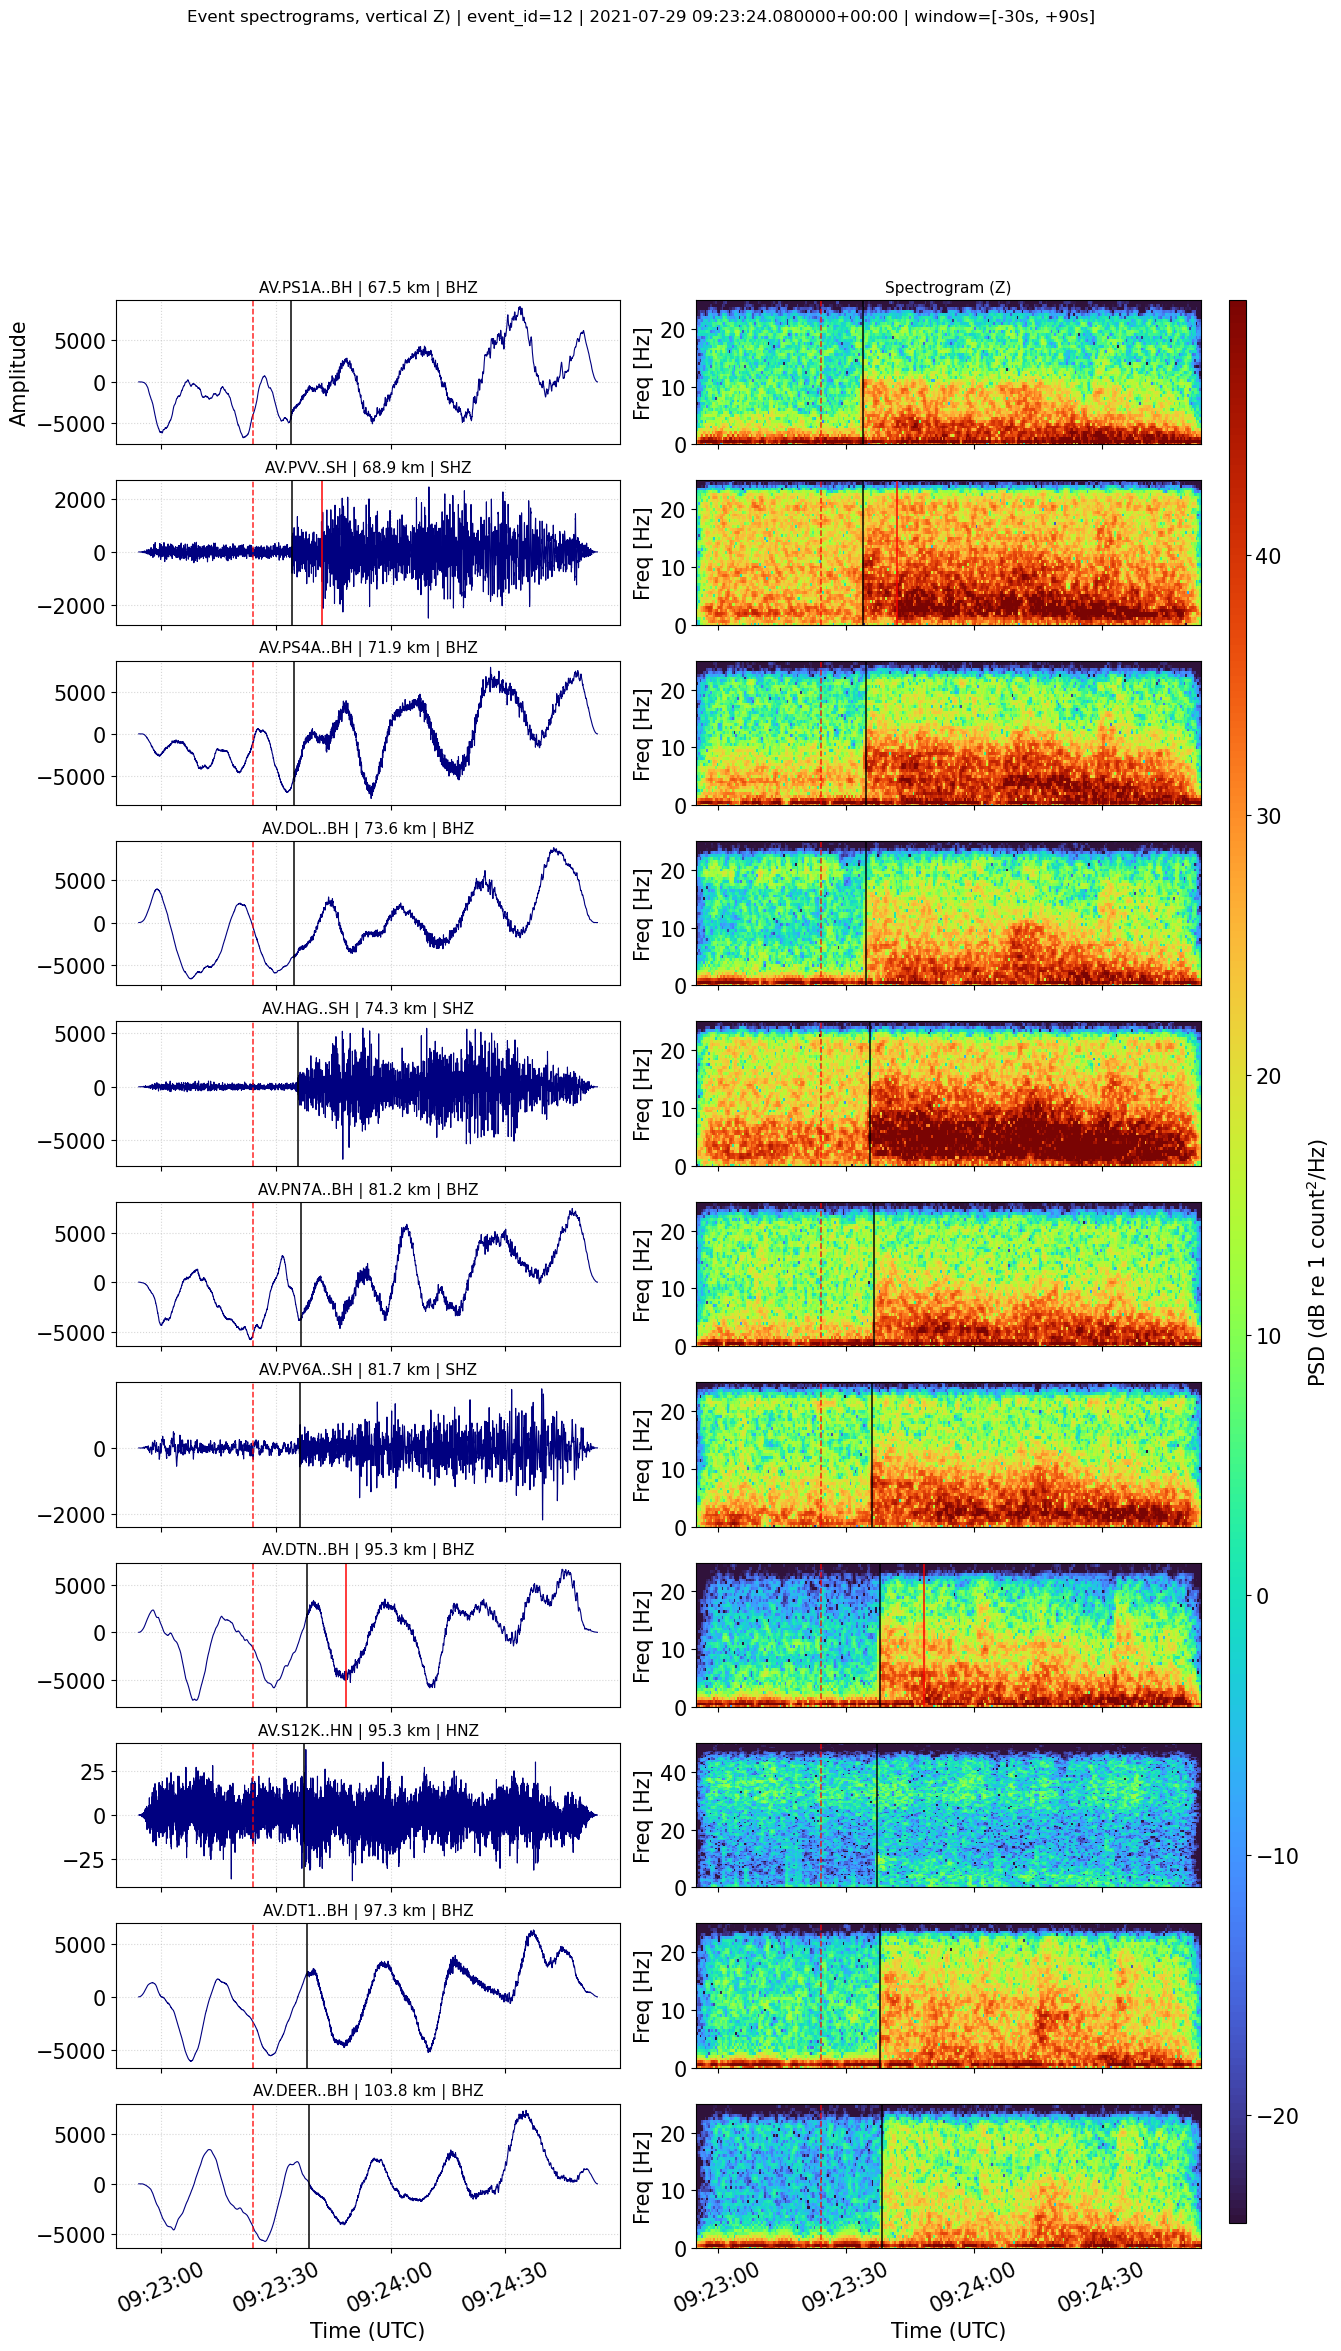

/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:8159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/spectrograms_event_2.png


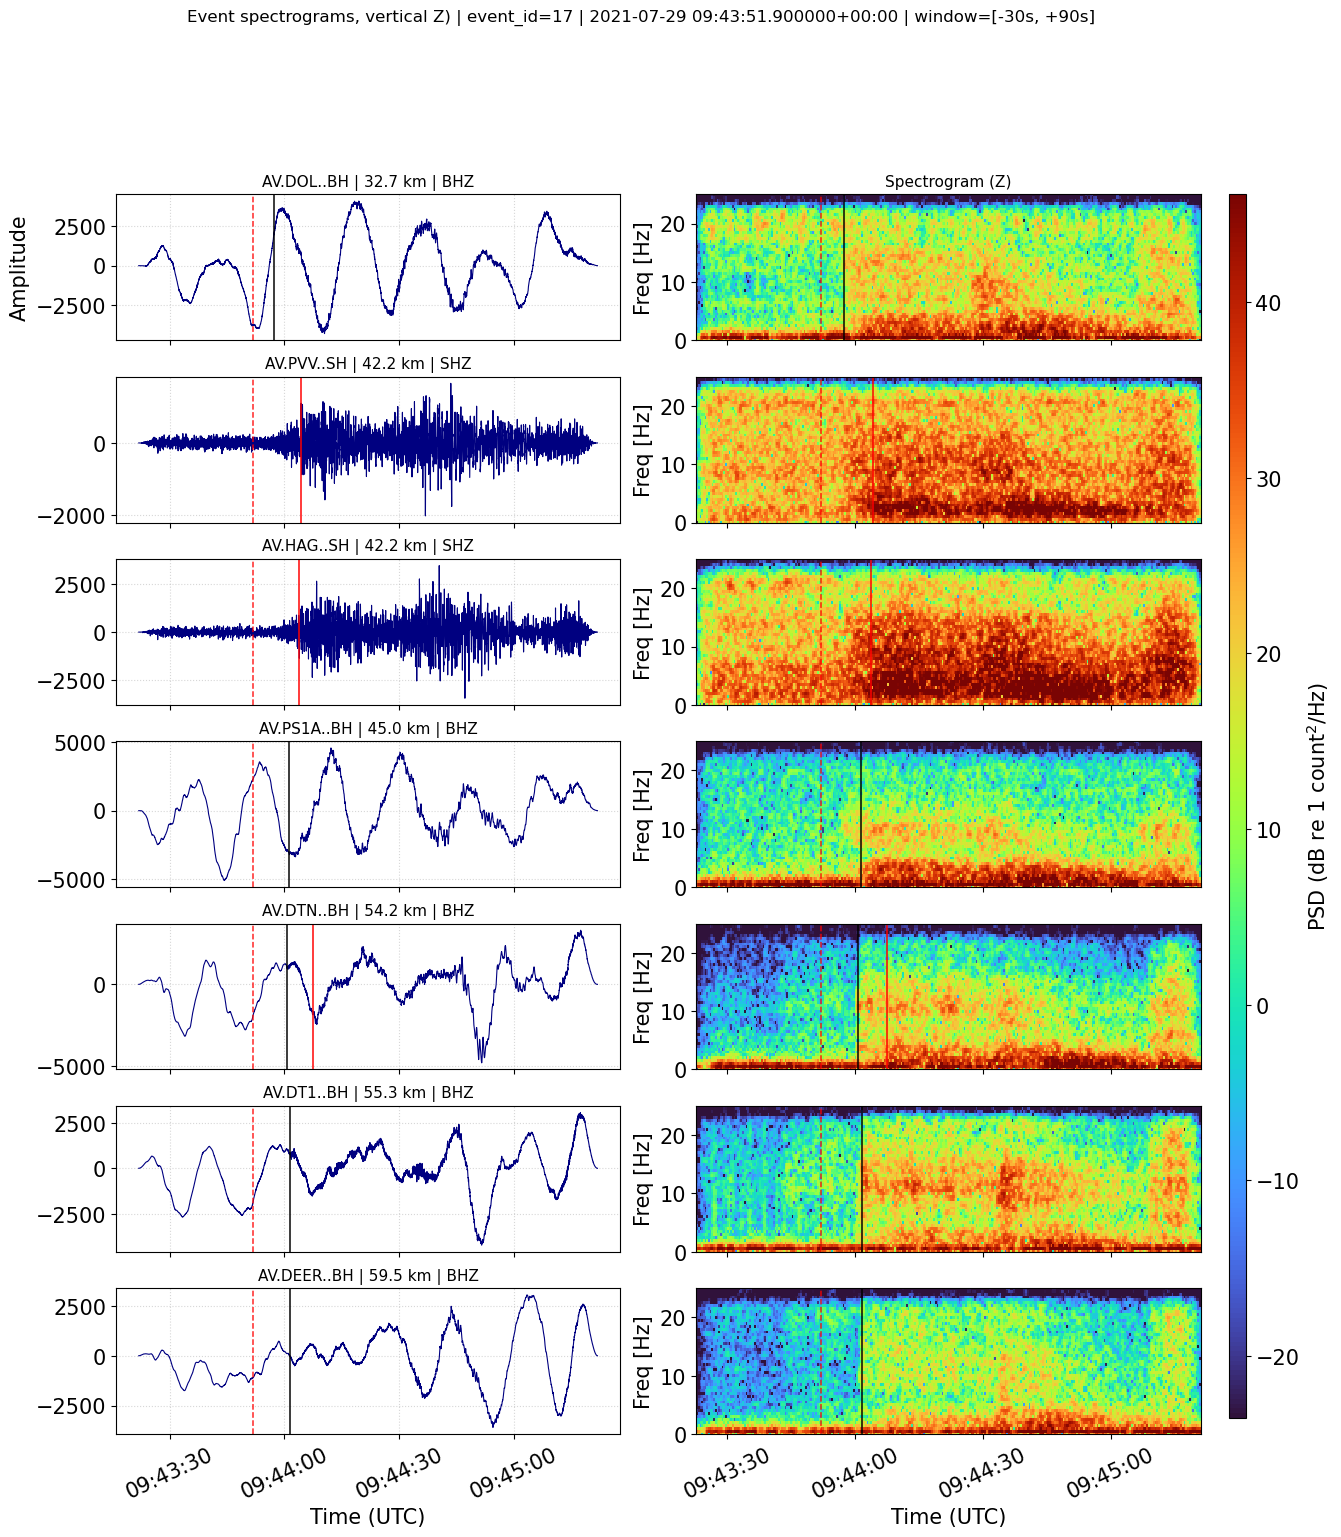

In [ ]:
if has_waveforms:
    for row_idx, row_event in wf_catalog.iloc[:N_WAVEFORM_EVENTS].iterrows():
        fig, axes, meta = h.plot_event_spectrograms_vertical_picks_only(
            row_event=row_event, picks=wf_picks, stations=wf_stations, cache=stream_cache, wf_index=wf_index,
            pre_s=30, post_s=90, window_s=2, overlap_frac=0.8, freq_min=0, freq_max=20)
        save(fig, f"spectrograms_event_{row_idx}.png", dpi=200)
        plt.show()

## 5. Location changes between pipeline stages
The same events located by GaMMA, HypoInverse and HypoDD; each segment joins two locations of one event.

38 events in all three stages | median horizontal shift: GaMMA->HypoInverse 19.87 km, HypoInverse->HypoDD 0.03 km
saved: /home/elizabeth/soft/src/QuickQuake/examples/pavlof_2021/data/images/visualization/location_changes_gamma_hypoinv_hypodd.pdf


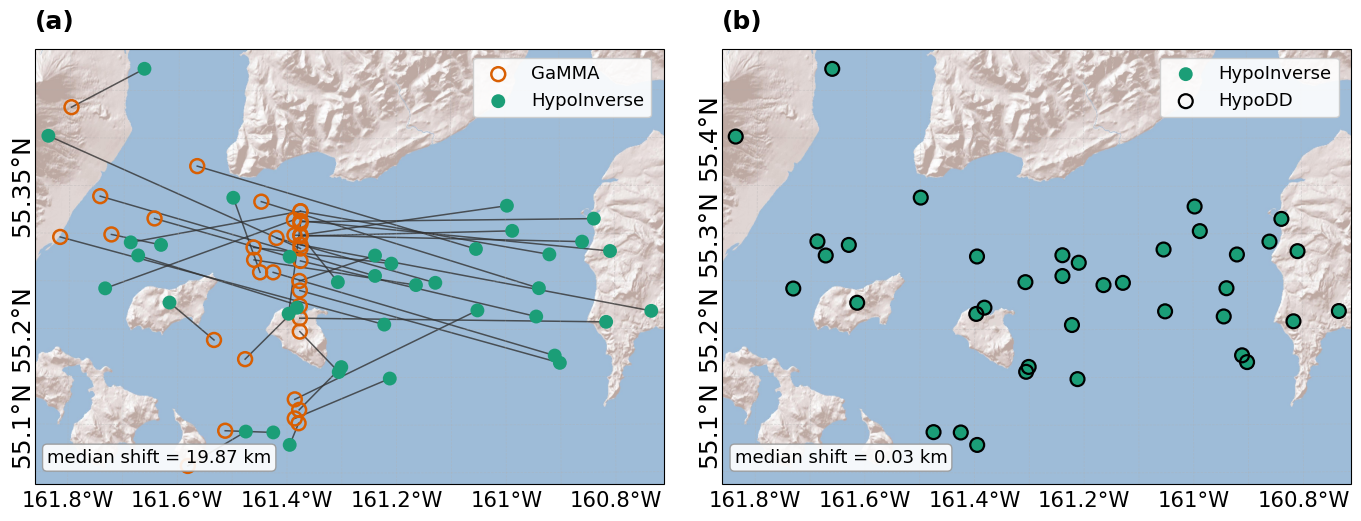

In [17]:
# HypoDD stage = the final QC-filtered catalog (as in the paper figures); use HYPODD_CSV for all relocated events
df_loc = h.build_location_evolution_df(GAMMA_CSV, HYPOINV_CSV, CATALOG_CSV, start=START, end=END)
print(f"{len(df_loc)} events in all three stages | median horizontal shift: "
      f"GaMMA->HypoInverse {df_loc['shift_gamma_hypoinv_km'].median():.2f} km, "
      f"HypoInverse->HypoDD {df_loc['shift_hypoinv_hypodd_km'].median():.2f} km")
fig, axes, drawn = h.plot_location_evolution_map(df_loc, max_events=1200, pad_lon=0.02, pad_lat=0.02,
                                                 x_tick_label_size=15.3, y_tick_label_size=18, legend_fontsize=13)
save(fig, "location_changes_gamma_hypoinv_hypodd.pdf")
plt.show()